# Load in the csv file 

In [1]:
import pandas as pd
from matplotlib import pyplot as plt
df=pd.read_csv('C:/Users/PC/Downloads/GitHub Project Datasets/world_bank_development_indicators.csv')

# Set the display format for numbers and create filters 

In [2]:
pd.set_option('display.float_format','{:,.0f}'.format)
coun=['India','China','Brazil','United States']
flt=(df['country'].isin(coun))

# Obtain the GDP data for the desired countries 

In [5]:
df_flt=df.loc[flt,['country','date','GDP_current_US']]


# Change the data obtained from a long format to a wide one

In [6]:
gdp_wide=df_flt.pivot_table(
    values='GDP_current_US',
    index='date',
    columns='country'
)

gdp_wide

country,Brazil,China,India,United States
date,,,,
1960-01-01,NaN,"59,716,249,311","37,029,883,876","543,300,000,000"
1961-01-01,NaN,"50,056,685,957","39,232,435,784","563,300,000,000"
1962-01-01,NaN,"47,209,186,415","42,161,481,858","605,100,000,000"
1963-01-01,NaN,"50,706,614,526","48,421,923,459","638,600,000,000"
1964-01-01,NaN,"59,708,125,204","56,480,289,941","685,800,000,000"
...,...,...,...,...
2018-01-01,"1,916,933,898,038","13,894,907,857,926","2,702,929,641,707","20,533,057,312,000"
2019-01-01,"1,873,288,205,186","14,279,968,506,243","2,835,606,256,616","21,380,976,119,000"
2020-01-01,"1,476,107,231,194","14,687,744,162,801","2,671,595,405,987","21,060,473,613,000"


# Clean the data to drop the NaN values and to filter out the data before the year 2000

In [7]:
gdp_wide.dropna(inplace=True)
gdp_wide=gdp_wide.loc['2000-01-01':]
gdp_wide

country,Brazil,China,India,United States
date,,,,
2000-01-01,"655,448,231,984","1,211,331,651,830","468,394,937,256","10,250,947,997,000"
2001-01-01,"559,983,634,799","1,339,400,897,153","485,441,014,539","10,581,929,774,000"
2002-01-01,"509,795,273,807","1,470,557,654,824","514,937,948,874","10,929,112,955,000"
2003-01-01,"558,233,745,652","1,660,280,543,871","607,699,285,436","11,456,442,041,000"
2004-01-01,"669,289,424,806","1,955,346,768,758","709,148,514,816","12,217,193,198,000"
2005-01-01,"891,633,839,853","2,285,961,149,904","820,381,595,511","13,039,199,193,000"
2006-01-01,"1,107,626,541,711","2,752,118,657,222","940,259,888,794","13,815,586,948,000"
2007-01-01,"1,397,114,486,471","3,550,327,803,025","1,216,736,438,842","14,474,226,905,000"
2008-01-01,"1,695,855,083,552","4,594,336,785,752","1,198,895,139,015","14,769,857,911,000"


# Plot the data using matplotlib 

([0,
  1,
  2,
  3,
  4,
  5,
  6,
  7,
  8,
  9,
  10,
  11,
  12,
  13,
  14,
  15,
  16,
  17,
  18,
  19,
  20,
  21,
  22],
 [Text(0, 0, '2000-01-01'),
  Text(1, 0, '2001-01-01'),
  Text(2, 0, '2002-01-01'),
  Text(3, 0, '2003-01-01'),
  Text(4, 0, '2004-01-01'),
  Text(5, 0, '2005-01-01'),
  Text(6, 0, '2006-01-01'),
  Text(7, 0, '2007-01-01'),
  Text(8, 0, '2008-01-01'),
  Text(9, 0, '2009-01-01'),
  Text(10, 0, '2010-01-01'),
  Text(11, 0, '2011-01-01'),
  Text(12, 0, '2012-01-01'),
  Text(13, 0, '2013-01-01'),
  Text(14, 0, '2014-01-01'),
  Text(15, 0, '2015-01-01'),
  Text(16, 0, '2016-01-01'),
  Text(17, 0, '2017-01-01'),
  Text(18, 0, '2018-01-01'),
  Text(19, 0, '2019-01-01'),
  Text(20, 0, '2020-01-01'),
  Text(21, 0, '2021-01-01'),
  Text(22, 0, '2022-01-01')])

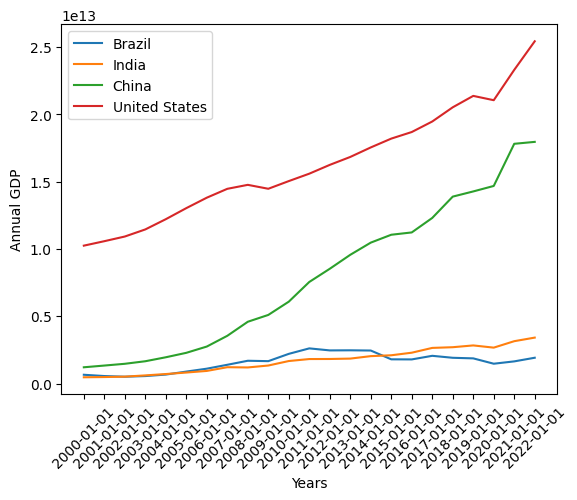

In [8]:

plt.plot(gdp_wide.index,gdp_wide.Brazil,label='Brazil')
plt.plot(gdp_wide.index,gdp_wide.India,label='India')
plt.plot(gdp_wide.index,gdp_wide.China,label='China')
plt.plot(gdp_wide.index,gdp_wide['United States'],label='United States')
plt.legend()
plt.xlabel('Years')
plt.ylabel('Annual GDP')
plt.xticks(rotation=45)

# Take the data for only the year 2000 and 2022 for the desired countries 

In [10]:
gdp_g=gdp_wide.loc[['2000-01-01','2022-01-01']]
gdp_g

country,Brazil,China,India,United States
date,,,,
2000-01-01,"655,448,231,984","1,211,331,651,830","468,394,937,256","10,250,947,997,000"
2022-01-01,"1,920,095,779,023","17,963,171,479,205","3,416,645,826,053","25,439,700,000,000"


# Calculate the average growth rates for GDP for the respective countries 

In [11]:
gdp_t=gdp_g.transpose()
gdp_t['Growth Rate (Average)']=(gdp_t['2022-01-01']/gdp_t['2000-01-01'])*100
gdp_wide=gdp_wide.loc['2000-01-01':]
gdp_t


date,2000-01-01,2022-01-01,Growth Rate (Average)
country,,,
Brazil,"655,448,231,984","1,920,095,779,023",293
China,"1,211,331,651,830","17,963,171,479,205","1,483"
India,"468,394,937,256","3,416,645,826,053",729
United States,"10,250,947,997,000","25,439,700,000,000",248
